# Predicting from an HMM

This notebook explains how to use an HMM to predict individual traits. In our example, we use a Gaussian HMM trained on synthetic resting-state-like fMRI data.

The HMM can be a useful description of patterns of brain dynamics across a group of subjects, and we may be interested in using this description to predict something about the individuals in this group. However, the information about individual brain dynamics given by the HMM needs to be extracted in a way that it can be used as features for regression or classification, and there are different approaches to doing that. 

**Summary metrics**

Alternatively, you can predict individual traits from summary metrics. Compared to the Fisher kernel, this offers the advantage of being more interpretable, but it contains less information (since the Fisher kernel can use all parameters of the HMM, i.e. the full description) and, as we show below, it often produces less accurate results.

The approach we have implemented here extracts one or more of the following summary metrics:

- fractional occupancies (FO): the fraction of the entire timeseries occupied by each state for each subject/session

- switching rate: the average rate of switching between states (as opposed to staying in the same state)

- lifetimes: the average lifetime (duration) of a state in the timeseries, where shorter lifetimes indicate faster dynamics

Since this “feature-engineering” approach does not require us to work in a particular space, we can simply use these features in standard machine learning models. The same features can also be used for statistical testing.

**The Fisher kernel**

The Fisher kernel (Jaakkola & Haussler, 1998) is a mathematically principled approach that uses the entire set (or a selection) of HMM parameters and constructs from them a kernel, representing between-subject similarities. This kernel can be used in a straightforward and computationally efficient way in any kernel-based prediction or classifier. This approach has been shown to be more accurate and reliable than other methods, including other kernels constructed from HMM-parameters (Ahrends, Woolrich, & Vidaurre, 2025).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from glhmm import glhmm, preproc, prediction, io, graphics

Load data

- data: simulated resting-state-like fMRI timeseries: 4800 timepoints from 100 subjects in a parcellation with 50 ROIs

- behav: simulated behavioural items from 100 subjects

- T_t: indices for beginning and start of each subject’s scanning session

- twins: matrix indicating family structure (subjects x subjects), zeros for unrelated subjects and positive values for related subjects (diagonal will be ignored)

- confounds: confounding variable for 100 subjects

In [2]:
# load data from csv files and convert to numpy arrays
data = pd.read_csv('./Prediction/tc_forpred.csv', header=None).to_numpy()
T_t = pd.read_csv('./Prediction/T_forpred.csv', header=None).to_numpy()
behav = np.squeeze(pd.read_csv('./Prediction/Y_forpred.csv', header=None).to_numpy())
twins = pd.read_csv('./Prediction/family_forpred.csv', header=None).to_numpy()
confounds = np.squeeze(pd.read_csv('./Prediction/confounds_forpred.csv', header=None).to_numpy())

# check that dimensions of input files are correct:
print(data.shape) # data should be (n_subjects*n_timepoints, n_parcels)
print(behav.shape) # behav should be (n_subjects, n_variables)
print(T_t.shape) # T_t should be (n_subjects, 2)
print(twins.shape) # twins should be (n_subjects, n_subjects)
print(confounds.shape) # confounds should be (n_subjects, n_confounds) or (n_subjects,)

(480000, 50)
(100,)
(100, 2)
(100, 100)
(100,)


In [3]:
T_t

array([[     0,   4800],
       [  4800,   9600],
       [  9600,  14400],
       [ 14400,  19200],
       [ 19200,  24000],
       [ 24000,  28800],
       [ 28800,  33600],
       [ 33600,  38400],
       [ 38400,  43200],
       [ 43200,  48000],
       [ 48000,  52800],
       [ 52800,  57600],
       [ 57600,  62400],
       [ 62400,  67200],
       [ 67200,  72000],
       [ 72000,  76800],
       [ 76800,  81600],
       [ 81600,  86400],
       [ 86400,  91200],
       [ 91200,  96000],
       [ 96000, 100800],
       [100800, 105600],
       [105600, 110400],
       [110400, 115200],
       [115200, 120000],
       [120000, 124800],
       [124800, 129600],
       [129600, 134400],
       [134400, 139200],
       [139200, 144000],
       [144000, 148800],
       [148800, 153600],
       [153600, 158400],
       [158400, 163200],
       [163200, 168000],
       [168000, 172800],
       [172800, 177600],
       [177600, 182400],
       [182400, 187200],
       [187200, 192000],


In [4]:
behav

array([-0.86365282,  0.07735909, -1.21411704, -1.11350074, -0.00684933,
        1.53263031, -0.76966591,  0.37137881, -0.2255844 ,  1.11735614,
       -1.0890643 ,  0.03255746,  0.55252702,  1.10061022,  1.5442119 ,
        0.08593113, -1.49159031, -0.74230184, -1.06158173,  2.35045722,
       -0.61560188,  0.74807678, -0.19241851,  0.88861043, -0.76484924,
       -1.40226897, -1.42237593,  0.48819391, -0.17737516, -0.19605349,
        1.41931015,  0.29158437,  0.19781105,  1.58769909, -0.80446596,
        0.69662442,  0.83508817, -0.24371514,  0.21567009, -1.16584393,
       -1.14795278,  0.10487472,  0.72225403,  2.58549125, -0.66689067,
        0.18733102, -0.08249443, -1.93302292, -0.43896615, -1.79467884,
        0.84037553, -0.88803208,  0.10009283, -0.54452893,  0.30352079,
       -0.60032656,  0.48996532,  0.73936312,  1.71188778, -0.19412354,
       -2.13835527, -0.83958875,  1.35459433, -1.07215529,  0.96095387,
        0.1240498 ,  1.43669662, -1.9609    , -0.19769823, -1.20

In [5]:
confounds

array([-1.91838188, -0.13106782, -0.76863167,  2.38995184,  0.07724568,
        0.37560745,  0.39556417, -0.11249909, -1.8290367 ,  2.09145219,
        0.35909312, -0.79434475, -0.22731164,  1.59382135,  0.15520563,
        0.17859563, -0.33773085, -1.52499189, -0.70940665, -0.86661663,
        0.07148111,  0.15562064, -0.18219139,  0.73101584, -0.34756807,
        0.23442401, -0.86772936, -0.98253859, -0.29357242,  0.82446964,
        0.19413317,  0.29769162, -0.71012508, -0.6876741 ,  0.57283812,
        0.4452176 , -1.32595926, -1.49987541,  1.01596823, -0.02751579,
       -0.16044558,  0.37883518, -0.10716072,  0.21283509,  0.46806392,
       -1.61607434,  0.01473801, -0.03776435,  0.403809  ,  0.30525439,
       -1.24311011,  0.13185919, -0.99947508, -0.35421346,  0.10558872,
        0.95542627,  0.46479898,  0.26670639, -1.42322334,  0.11105731,
        1.17285539, -2.11558332,  0.46216114, -2.45990316, -0.30485718,
        0.39823325, -1.70578655,  0.75940981,  0.20323762,  0.95

In [6]:
twins[0]

array([-1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
      dtype=int64)

In [7]:
data_preproc,_,_ = preproc.preprocess_data(data, T_t)

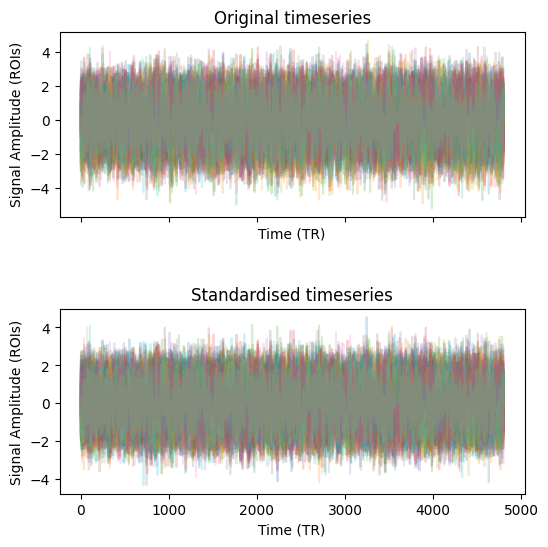

In [8]:
# for one example subject
fig, (ax0, ax1) = plt.subplots(nrows=2, sharex=True, figsize=(6, 6))
ax0.plot(data[0:4800,:], alpha=0.2)
ax0.set_xlabel("Time (TR)")
ax0.set_ylabel("Signal Amplitude (ROIs)")
ax0.title.set_text("Original timeseries")
ax1.plot(data_preproc[0:4800,:], alpha=0.2)
ax1.set_xlabel("Time (TR)")
ax1.set_ylabel("Signal Amplitude (ROIs)")
ax1.title.set_text("Standardised timeseries")
plt.subplots_adjust(hspace=0.5)
plt.show()

In [9]:
del data

**Train Model**

In [10]:
#train or load model
hmm = io.load_hmm('./Prediction/hmm_pred.pkl')

# np.random.seed(123)
# hmm = glhmm.glhmm(model_beta='no', K=6, covtype='full')
# hmm.train(X=None, Y=data_preproc, indices=T_t)

**Inspecting model parameters**

In [11]:
K = hmm.hyperparameters["K"] # the number of states
q = data_preproc.shape[1] # the number of parcels/channels
init_stateP = hmm.Pi # the initial state probabilities
TP = np.zeros(shape=(K, K))
TP = hmm.P # the transition probability matrix
state_means = np.zeros(shape=(q, K))
state_means = hmm.get_means() # the state means in the shape (no. features, no. states)
state_FC = np.zeros(shape=(q, q, K))
for k in range(K):
    state_FC[:,:,k] = hmm.get_covariance_matrix(k=k) # the state covariance matrices in the shape (no. features, no. features, no. states)

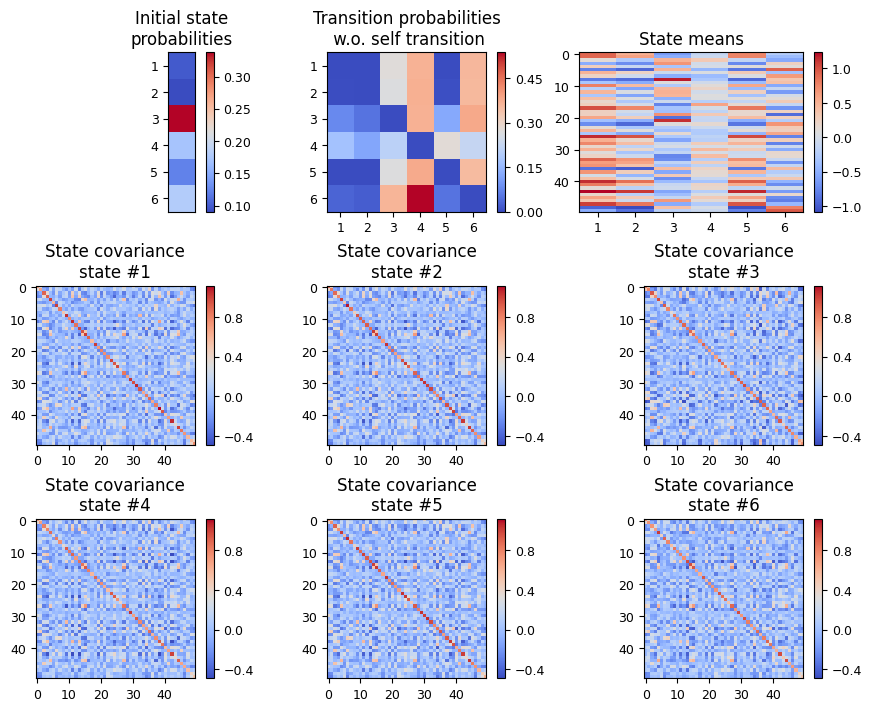

In [12]:
# Plot the HMM parameter estimates
graphics.plot_state_prob_and_covariance(init_stateP, TP, state_means,
                                        state_FC, cmap='coolwarm')

# Predicting individual traits from an HMM using cross-validation

To predict from an HMM using cross-validation, you can use the function predict_phenotype from the prediction module. This function goes through the following steps:

1. create the Fisher kernel or extract summary metrics from a group-level HMM (the features are normalised or the kernel is centered during CV)

2. fit prediction model: using nested cross-validation, where the inner CV loops are used to optimise hyperparameters via grid search. (optionally) deconfounding during CV, otherwise the target variables are only normalised (also during CV) (optionally) accounting for group/family structure so that related subjects are never split across folds

3. predict on test set

4. evaluate predictive performance

**Predicting using the Fisher kernel**

The Fisher kernel allows using either all or a selection of HMM parameters for a prediction/classification, and it is constructed from the HMM in a mathematically principled manner that preserves the underlying structure of the model parameters. This approach is recommended because it tends to predict more accurately and does so more robustly than other methods.

In [13]:
np.random.seed(123)

options = {}
# general options:
options['nfolds'] = 10 # number of folds for inner & outer CV loops
# options['group_structure'] = twins # group structure that CV should take into account, in this case the family relations. This option makes sure that related subjects are never split across CV folds
# when not using group/family structure, simply don't specify this option
# options['confounds'] = confounds # confounding variables (here sex and head motion)
# when not using confounds, simply don't specify this option
# optional outputs:
options['return_scores'] = True
options['return_models'] = True
options['return_hyperparams'] = True
# Fisher kernel options:
options['shape'] = 'linear'
options['incl_Mu'] = True # include state means
options['incl_Sigma'] = True # include state covariances
# the initial state probabilities and the transition probabilities
# are used by default, but can be excluded by setting options['incl_Pi']
# and options['incl_P'], respectively, to False

# use HMM trained/loaded above and standardised timeseries to predict subjects' age:
pred_FK = prediction.predict_phenotype(hmm, data_preproc, behav, T_t, predictor='Fisherkernel', estimator='KernelRidge', options=options)

In [14]:
# print(pred_FK['corr_deconf']) # the correlation coefficient
# print(pred_FK['scores_deconf']) # the coefficients of determination
print(pred_FK['corr']) # the correlation coefficient
print(pred_FK['scores']) # the coefficients of determination
print(pred_FK['hyperparams']) # the regularisation parameters
pred_FK['models'][0] # the first estimated model

0.7941267498525395
[0.6013801207261673, 0.6965621284048777, 0.5621094947857105, 0.3098232781435948, 0.6401746743768735, 0.21043846247433262, 0.6899238152727493, 0.4652015014640447, 0.5925674256002567, 0.412652514854829]
[0.1, 0.1, 0.1, 0.0001, 0.0001, 0.1, 0.0001, 0.0001, 0.1, 0.0001]


,estimator,KernelRidge(k...'precomputed')
,param_grid,{'alpha': array([0.0001... 0.1 ])}
,scoring,None
,n_jobs,None
,refit,True
,cv,KFold(n_split...shuffle=False)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,0.1


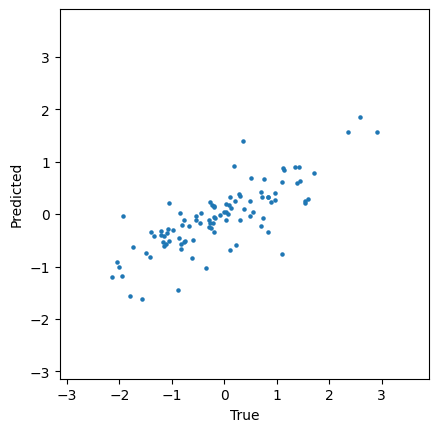

In [15]:
plt.scatter(behav, pred_FK['behav_pred'], s=5, color='tab:blue')
minval = min((min(behav), min(pred_FK['behav_pred'])))
maxval = max((max(behav), max(pred_FK['behav_pred'])))
plt.xlim((minval-1),(maxval+1))
plt.ylim((minval-1),(maxval+1))
plt.gca().set_xlabel('True')
plt.gca().set_ylabel('Predicted')
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

**Predicting using summary metrics**

The second option is to extract summary metrics from a trained HMM and use these as features for a prediction. Which metrics to include should be specified in options['metrics']. At the moment, possible summary metrics include state fractional occupancies ('FO'), lifetimes ('lifetimes'), and switching rates ('switching_rate').

In [18]:
np.random.seed(123)

options = {}
# general options:
options['nfolds'] = 10 # number of folds for inner & outer CV loops
# options['group_structure'] = twins # group structure that CV should take into account, in this case the family relations. This option makes sure that related subjects are never split across CV folds
# when not using group/family structure, simply don't specify this option
# options['confounds'] = confounds # confounding variables (here sex and head motion)
# when not using confounds, simply don't specify this option
# optional outputs:
options['return_scores'] = True
options['return_models'] = True
options['return_hyperparams'] = True
# summary metrics options:
options['metrics'] = ('FO', 'lifetimes', 'switching_rate')
# include the fractional occupancies (FO), the state lifetimes, and the switching rates

# use HMM trained/loaded above and standardised timeseries to predict subjects' age:
behav_2d = np.asarray(behav).reshape(1, -1)
pred_summ = prediction.predict_phenotype(hmm, data_preproc, behav, T_t, predictor='summary_metrics', estimator='Ridge', options=options)

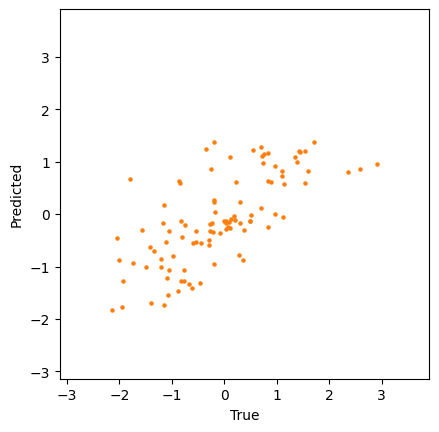

In [20]:
plt.scatter(behav, pred_summ['behav_pred'], s=5, color='tab:orange')
minval = min((min(behav), min(pred_summ['behav_pred'])))
maxval = max((max(behav), max(pred_summ['behav_pred'])))
plt.xlim((minval-1),(maxval+1))
plt.ylim((minval-1),(maxval+1))
plt.gca().set_xlabel('True')
plt.gca().set_ylabel('Predicted')
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

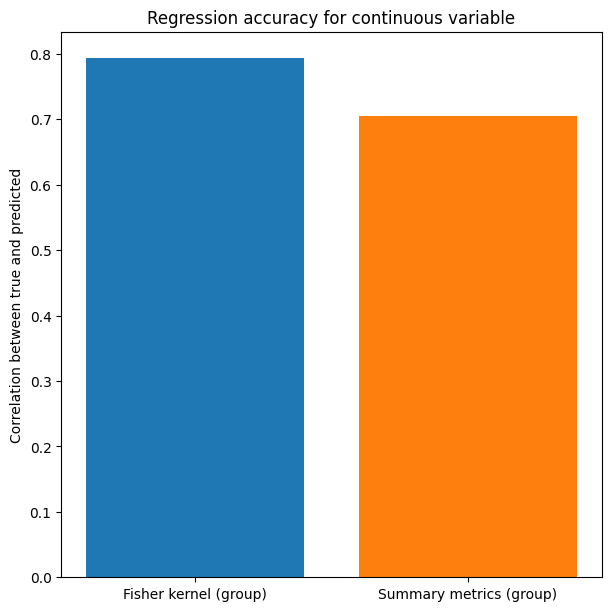

In [22]:
fig, ax = plt.subplots(layout="constrained", figsize=(6, 6))
features = ["Fisher kernel (group)", "Summary metrics (group)"]
pred_acc = [pred_FK['corr'], pred_summ['corr']]
bar_colors = ['tab:blue', 'tab:orange']
ax.bar(features, pred_acc, color=bar_colors)
ax.set_ylabel('Correlation between true and predicted')
ax.set_title('Regression accuracy for continuous variable')
plt.show()

# Classifying from HMMs

Analogous to predict_phenotype, the function classify_phenotype allows classifying from an HMM. We have simulated timecourses for two groups of subjects, where the first 50 subjects belong to group 1 and the second 50 subjects belong to group 2. 

In [ ]:
data_c = pd.read_csv('./Prediction/tc_forclass.csv', header=None).to_numpy()
group = np.ones(100)
group[50:100] = 2 # create classes: the first 50 subjects are group 1, the second 50 subjects are group 2
T = np.repeat(1200,100) # we have simulated 100 subjects with 1200 timepoints each
T_tc = glhmm.auxiliary.make_indices_from_T(T)

In [ ]:
data_c.shape

(120000, 50)

In [ ]:
data_c_preproc,_,_ = preproc.preprocess_data(data_c, T_tc)
del data_c

In [ ]:
hmm_c = io.load_hmm('./Prediction/hmm_class.pkl')

# or train model on the classification data

# np.random.seed(123)
# hmm_c = glhmm.glhmm(model_beta='no', K=6, covtype='full')
# hmm_c.train(X=None, Y=data_c_preproc, indices=T_tc)s

We will first classify using the Fisher kernel approach:

In [ ]:
np.random.seed(123)

options = {}
# general options:
options['nfolds'] = 10 # number of folds for inner & outer CV loops
# options['group_structure'] = twins # group structure that CV should take into account, in this case the family relations. This option makes sure that related subjects are never split across CV folds
# optional outputs:
options['return_scores'] = True
options['return_models'] = True
options['return_hyperparams'] = True
options['return_prob'] = True # for classification, you can optionally also return the probabilities for each class, but note that this will take longer
# Fisher kernel options:
options['shape'] = 'linear'
options['incl_Mu'] = True # include state means
options['incl_Sigma'] = True # include state covariances

# use HMM trained/loaded above and standardised timeseries to classify sex using Fisher kernel method:
classif_FK = prediction.classify_phenotype(hmm_c, data_c_preproc, group, T_tc, predictor='Fisherkernel', estimator='SVM', options=options)

In this artificial dataset, the Fisher kernel can thus classify the groups at 100% accuracy. Again, since there is no between-subject noise, this is expected to be an easy classification problem. If we use the summary metrics approach on the other hand, the features cannot directly access an effect like the one we have simulated (where one state’s mean is different between the two groups). It may only indirectly be represented, e.g. in the state fractional occupancies.

In [ ]:
np.random.seed(123)

options = {}
# general options:
options['nfolds'] = 10 # number of folds for inner & outer CV loops
# options['group_structure'] = twins # group structure that CV should take into account, in this case the family relations. This option makes sure that related subjects are never split across CV folds
# optional outputs:
options['return_scores'] = True
options['return_models'] = True
options['return_hyperparams'] = True
options['return_prob'] = True # for classification, you can optionally also return the probabilities for each class, but note that this will take longer
# summary metrics options:
options['metrics'] = ('FO', 'lifetimes', 'switching_rate')

# use HMM trained/loaded above and standardised timeseries to classify sex from summary metrics:
classif_summ = prediction.classify_phenotype(hmm_c, data_c_preproc, group, T_tc, predictor='summary_metrics', estimator='SVM', options=options)

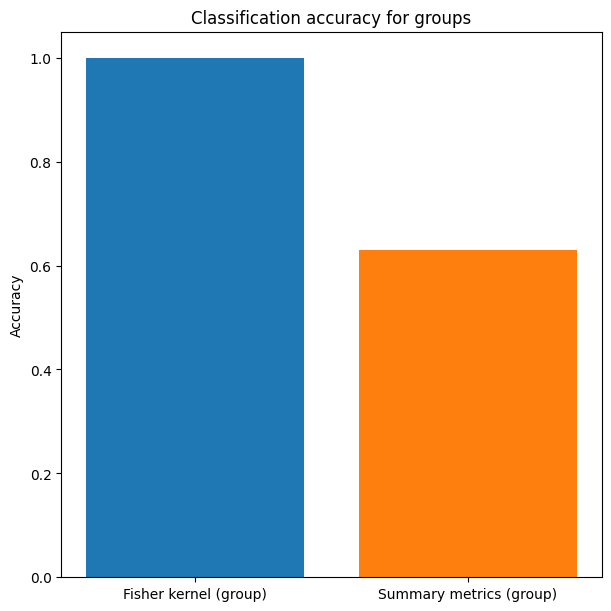

In [ ]:
fig, ax = plt.subplots(layout="constrained", figsize=(6, 6))
features = ["Fisher kernel (group)", "Summary metrics (group)"]
classif_acc = [classif_FK['acc'], classif_summ['acc']]
bar_colors = ['tab:blue', 'tab:orange']
ax.bar(features, classif_acc, color=bar_colors)
ax.set_ylabel('Accuracy')
ax.set_title('Classification accuracy for groups')
plt.show()